# Design PGA ($PGA_d$): lowest-cost design and the value of a soil investigation

This notebook finds the design PGA, $PGA_d$, that gives the lowest total cost for a building, and estimates how much a soil investigation (a cross-hole survey) is worth.

## The problem

Designing to a higher $PGA_d$ costs more to build, but it reduces the losses in future earthquakes. The best $PGA_d$ is the one that minimises the **sum** of the two costs. The stiffness of the soil ($V_{S30}$) changes the shaking at the site, so it also changes the best answer. If $V_{S30}$ is uncertain, a soil investigation can tell us which $PGA_d$ to choose.

## The steps

1. **Site hazard:** how often each PGA is exceeded at the site (depends on $V_{S30}$)
2. **Vulnerability:** the loss caused by each PGA, for four design levels
3. **Expected annual loss (EAL):** vulnerability combined with the hazard
4. **Expected future loss (EFL):** the EAL accumulated over 50 years, discounted
5. **Combined cost** = EFL + seismic design cost. Its minimum gives the optimal $PGA_d$
6. **Soil profiles:** several possible $V_{S30}$ values from the MASW uncertainty
7. **Value of information:** how much the expected cost falls if the true $V_{S30}$ is known

All PGA values are in **g**. The functions are in `pgad_cost.py`, which must be in the same folder as this notebook, together with the vulnerability CSV.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pgad_cost as pc

vulnerability = pc.load_vulnerability("Gkimprixis_PGAd_vulnerbility.csv")

/Users/susannakeith/opt/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/susannakeith/opt/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Site hazard

`site_maf(pga, vs30)` returns the mean annual frequency (MAF) of exceeding a PGA at a site.

* The starting point is the ESHM20 hazard curve for reference rock ($V_{S30}$ = 800 m/s), given as a probability of exceedance in 50 years. It is converted to an annual frequency.
* The site curve is the reference curve shifted by the amplification factor $F_s = (V_{S30}/800)^{-0.3019}$, calculated by `amplification_factor(vs30)`. Softer soil (lower $V_{S30}$) gives a larger $F_s$ and a higher hazard.

Choose the site $V_{S30}$:

In [2]:
vs30 = 197     # site Vs30 [m/s]

print(f"Amplification factor Fs = {float(pc.amplification_factor(vs30)):.3f}")
print(f"MAF of exceeding 0.3 g:  reference rock = {float(pc.site_maf(0.3, pc.V_REF)):.2e},  this site = {float(pc.site_maf(0.3, vs30)):.2e}")

Amplification factor Fs = 1.527
MAF of exceeding 0.3 g:  reference rock = 3.98e-03,  this site = 9.16e-03


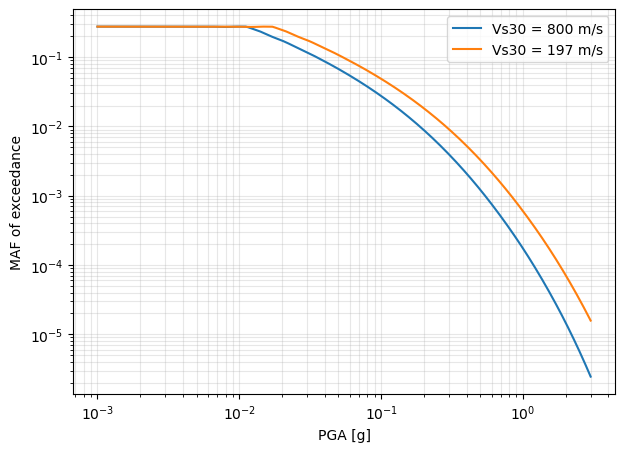

In [3]:
plt.figure(figsize=(7, 5))
pc.plot_site_hazard([pc.V_REF, vs30])
plt.show()

## 2. Vulnerability

The vulnerability CSV has four curves, one for each design level $PGA_d$ = 0, 0.1, 0.3 and 0.5 g. Each gives the loss ratio (loss as a fraction of building value) at a given PGA. A building designed to a higher $PGA_d$ loses less.

`vulnerability_function(pga, vulnerability, column)` returns the loss ratio at any PGA by linear interpolation.

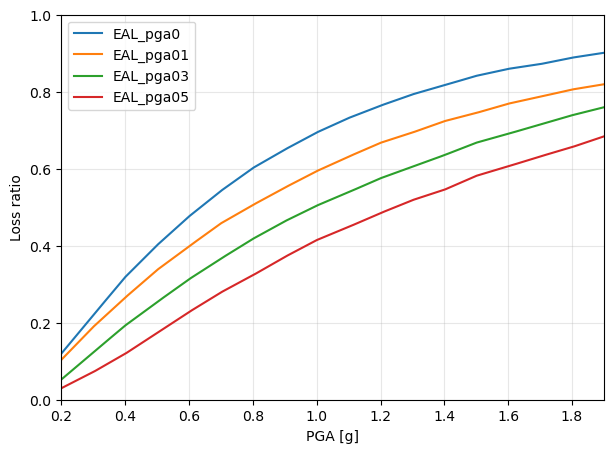

In [4]:
plt.figure(figsize=(7, 5))
pc.plot_vulnerability(vulnerability)
plt.show()

## 3. Expected annual loss (EAL)

`calculate_eals(vs30, vulnerability)` combines the hazard and the vulnerability. For each vulnerability curve it adds up the loss at each PGA, weighted by how often that PGA occurs, over the PGA range 0.2 to 1.9 g.

It returns one EAL (loss ratio per year) for each of the four design levels.

In [5]:
eals = pc.calculate_eals(vs30, vulnerability)

for name, value in eals.items():
    print(f"{name}: {value:.6f}")

EAL_pga0: 0.004987
EAL_pga01: 0.004244
EAL_pga03: 0.003018
EAL_pga05: 0.002035


## 4. EAL and EFL as functions of $PGA_d$

We only have the EAL at four design levels. To get it at any $PGA_d$:

* `fit_eal_function(eals)` multiplies each EAL by the building value (€) and fits $EAL(PGA_d) = B\,e^{-C\,PGA_d}$. It returns $B$ and $C$.
* `efl_function(pga_d, B, C)` converts the EAL to the expected future loss over $t$ = 50 years with a discount rate $\lambda$ = 5 %:

$$EFL = EAL \cdot \frac{1 - e^{-\lambda t}}{\lambda}$$

In [6]:
B, C = pc.fit_eal_function(eals)
print(f"EAL(PGA_d) = {B:,.0f} * exp(-{C:.3f} * PGA_d)")
print()

pga_d_options = [0.0, 0.1, 0.3, 0.5]
for pga_d, efl in zip(pga_d_options, pc.efl_function(pga_d_options, B, C)):
    print(f"PGA_d = {pga_d:.1f} g:  EFL = €{efl:,.0f}")

EAL(PGA_d) = 3,282 * exp(-1.646 * PGA_d)

PGA_d = 0.0 g:  EFL = €84,978
PGA_d = 0.1 g:  EFL = €72,081
PGA_d = 0.3 g:  EFL = €51,862
PGA_d = 0.5 g:  EFL = €37,314


## 5. Combined cost and the optimal $PGA_d$

* `seismic_design_cost(pga_d)` gives the extra construction cost (€) of designing to $PGA_d$.
* `cost_curves(vs30, vulnerability)` does steps 3 and 4 and adds the design cost. It returns a table with the EFL, the design cost and the combined cost at each $PGA_d$.
* `minimum_cost(curves)` returns the $PGA_d$ with the lowest combined cost, and that cost.

In [7]:
curves = pc.cost_curves(vs30, vulnerability)
curves.head()

,PGAd,EFL,Design_cost,Combined
0,0.000000,84978.270712,0.000000,84978.270712
1,0.003006,84558.830801,38.537074,84597.367875
2,0.006012,84141.461182,77.074148,84218.535330
3,0.009018,83726.151636,115.611222,83841.762858
4,0.012024,83312.891995,154.148297,83467.040292


Optimal PGA_d = 0.2645 g
Minimum combined cost = €71,173


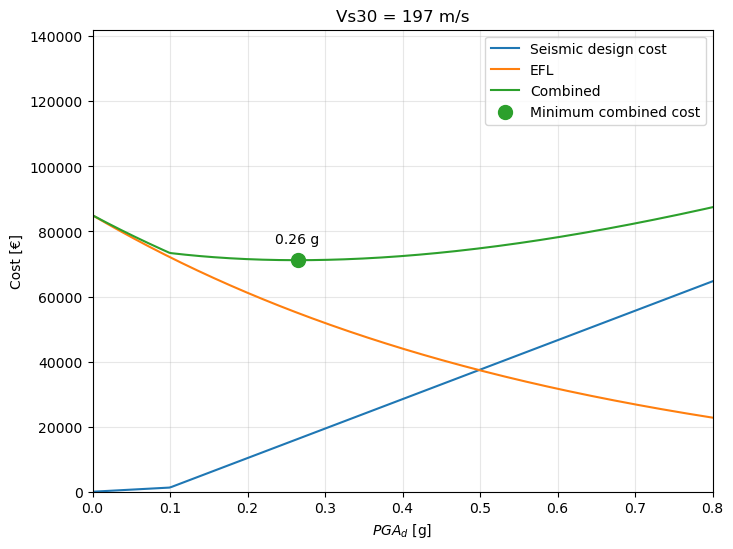

In [8]:
pga_d_min, cost_min = pc.minimum_cost(curves)
print(f"Optimal PGA_d = {pga_d_min:.4f} g")
print(f"Minimum combined cost = €{cost_min:,.0f}")

plt.figure(figsize=(8, 6))
pc.plot_cost_curves(curves, vs30)
plt.show()

## 6. Soil profiles

In practice $V_{S30}$ is not known exactly. A MASW survey gives a range of possible stiffnesses for each of two soil layers, and each possible combination is one possible profile.

`generate_profiles(...)` picks random profiles within those ranges (the `seed` makes the result repeatable). $V_{S30}$ of each profile is the harmonic average over the top 30 m:

$$V_{S30} = \frac{30}{d_1/V_{S1} + d_2/V_{S2}}$$

Here: layer 1 is 10 m thick with $V_{S1}$ from 100 to 300 m/s, layer 2 is 20 m thick with $V_{S2}$ from 200 to 800 m/s. Replace these with your own MASW ranges.

In [9]:
profiles = pc.generate_profiles(n=10, vs1_range=(100, 300), vs2_range=(200, 800),
                                thickness=(10, 20), seed=42)
profiles.round(1)

,Profile,Vs1,Vs2,Thickness1,Thickness2,Vs30
0,1,174.9,212.4,10,20,198.2
1,2,290.1,781.9,10,20,499.6
2,3,246.4,699.5,10,20,433.7
3,4,219.7,327.4,10,20,281.4
4,5,131.2,309.1,10,20,212.9
5,6,131.2,310.0,10,20,213.2
6,7,111.6,382.5,10,20,211.5
7,8,273.2,514.9,10,20,397.6
8,9,220.2,459.2,10,20,337.2
9,10,241.6,374.7,10,20,316.6


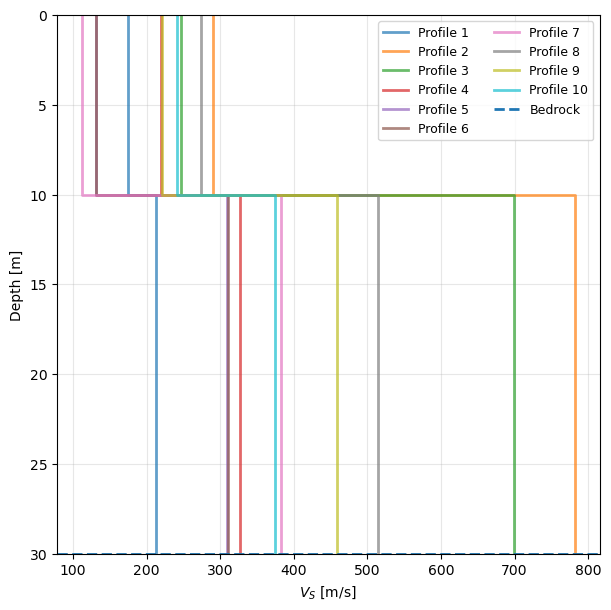

In [10]:
plt.figure(figsize=(7, 7))
pc.plot_profiles(profiles)
plt.show()

## 7. Cost curves for every profile

`profile_cost_curves` repeats the combined-cost calculation for each profile's $V_{S30}$. `profile_results` gives the optimal $PGA_d$ and minimum cost of each profile. A softer profile (lower $V_{S30}$) has a higher optimal $PGA_d$.

In [11]:
combined_curves = pc.profile_cost_curves(profiles, vulnerability)
pc.profile_results(profiles, combined_curves).round(3)

,Profile,Vs1,Vs2,Vs30,PGAd_min,Minimum_cost
0,1,174.908,212.351,198.207,0.262,70989.771
1,2,290.143,781.946,499.642,0.099,44103.845
2,3,246.399,699.466,433.665,0.102,47772.643
3,4,219.732,327.403,281.434,0.153,60411.787
4,5,131.204,309.095,212.883,0.240,68840.868
5,6,131.199,310.043,213.178,0.240,68799.210
6,7,111.617,382.545,211.456,0.243,69043.495
7,8,273.235,514.854,397.643,0.102,50142.564
8,9,220.223,459.167,337.209,0.102,54926.849
9,10,241.615,374.737,316.593,0.117,56841.909


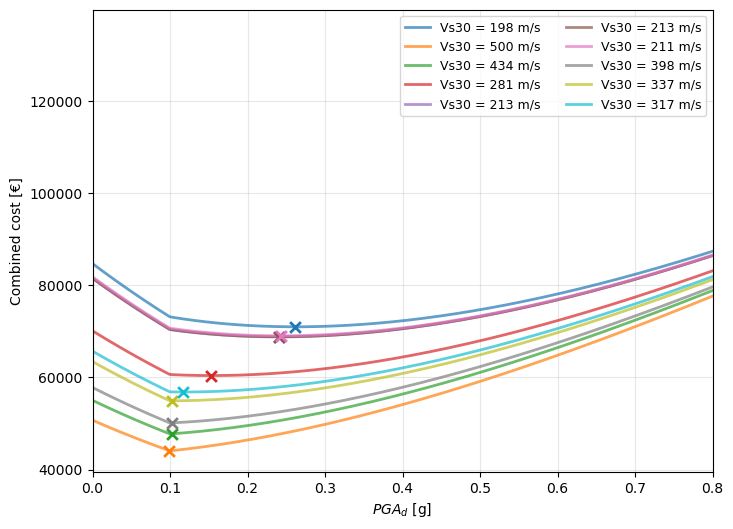

In [12]:
plt.figure(figsize=(8, 6))
pc.plot_profile_cost_curves(profiles, combined_curves)
plt.show()

## 8. Value of information

The 10 profiles are 10 possible true soil conditions, all assumed equally likely. We compare two situations:

* **Without the cross-hole survey:** the true profile is unknown, so one $PGA_d$ must be chosen for all cases. The best choice has the lowest **average** cost across the profiles.
* **With the cross-hole survey (perfect information):** the true $V_{S30}$ is known, so the best $PGA_d$ is chosen for that profile. The expected cost is the average of each profile's **own minimum** cost.

The **value of information (VoI)** is the difference: the most the survey could save on average.

`cost_matrix` gives the total cost of every decision (columns) for every possible true profile (rows). `value_of_information` then does the comparison.

In [13]:
costs = pc.cost_matrix(profiles, vulnerability)

cost_table = pd.DataFrame(costs, index=profiles["Profile"],
                          columns=[f"{d:.2f} g" for d in pc.PGAD_DECISIONS])
cost_table.round(0)

,0.00 g,0.10 g,0.20 g,0.25 g,0.30 g,0.35 g,0.40 g,0.50 g
Profile,,,,,,,,
1,84704.0,73142.0,71290.0,71001.0,71093.0,71536.0,72301.0,74700.0
2,50723.0,44070.0,46421.0,48001.0,49822.0,51864.0,54109.0,59144.0
3,55033.0,47746.0,49556.0,50896.0,52495.0,54332.0,56388.0,61086.0
4,70113.0,60635.0,60571.0,61078.0,61908.0,63033.0,64430.0,67957.0
5,81545.0,70432.0,68965.0,68848.0,69099.0,69689.0,70591.0,73233.0
6,81485.0,70380.0,68920.0,68807.0,69061.0,69654.0,70558.0,73205.0
7,81838.0,70683.0,69181.0,69048.0,69284.0,69860.0,70749.0,73369.0
8,57819.0,50125.0,51586.0,52771.0,54227.0,55932.0,57866.0,62347.0
9,63439.0,54925.0,55687.0,56562.0,57731.0,59170.0,60858.0,64903.0


In [14]:
result = pc.value_of_information(costs)

print(f"Without information:       optimal PGA_d = {result['optimal_without_info']:.2f} g, expected cost = €{result['cost_without_info']:,.0f}")
print(f"With perfect information:  expected cost = €{result['cost_with_info']:,.0f}")
print(f"Value of information = €{result['VoI']:,.0f}")

Without information:       optimal PGA_d = 0.10 g, expected cost = €59,900
With perfect information:  expected cost = €59,200
Value of information = €700


In [15]:
pd.DataFrame({"Vs30": profiles["Vs30"],
              "Optimal PGA_d": result["optimal_per_profile"],
              "Minimum cost": result["min_cost_per_profile"]}).round(1)

,Vs30,Optimal PGA_d,Minimum cost
0,198.2,0.2,71001.2
1,499.6,0.1,44070.4
2,433.7,0.1,47746.4
3,281.4,0.2,60570.6
4,212.9,0.2,68847.9
5,213.2,0.2,68806.8
6,211.5,0.2,69047.7
7,397.6,0.1,50124.6
8,337.2,0.1,54925.5
9,316.6,0.1,56863.4


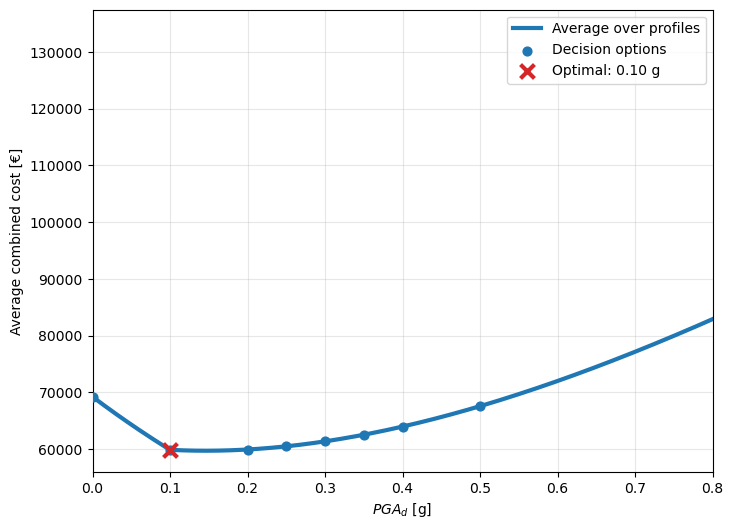

In [16]:
plt.figure(figsize=(8, 6))
pc.plot_average_cost(combined_curves, costs)
plt.show()

## Notes

* The hazard curve, the vulnerability curves, the building values (€) and the seismic design cost function come from the original analysis.
* The EAL only includes PGA between 0.2 and 1.9 g, the range of the vulnerability data.
* All profiles are assumed equally likely. The VoI is for *perfect* information, so it is the upper limit of what a cross-hole survey could be worth.
* Results are for the single building and cost assumptions above.